# Module 11 · Notebook 2 of 3 — The Real Model: Multimodal Fusion on TCGA-BRCA

**BIOT 6900 · AI-Powered Biotech Workflows**

In Notebook 1 you watched the three fusion strategies win and lose on clean, synthetic data.
Now the training wheels come off. The same four functions you read there get pointed at **real
breast-cancer patients** — and real data brings three things the toy never did.

| | Toy (Notebook 1) | Real (this notebook) |
|---|---|---|
| **Data** | synthetic, clean, complete | TCGA-BRCA: expression + pathology + clinical |
| **Modalities** | three equal random blocks | ~20k-gene expression, a 1,024-d image embedding, ~15 clinical fields |
| **Missingness** | none | real — not every patient has a usable slide |
| **The task** | a planted label | predict **5-year survival** |

**The target.** Predict whether a patient is alive at 5 years. No single modality predicts it
well; the interesting question is what combining them buys — and at what cost.

> **Imaging note.** Pathology can't be *downloaded* as a per-patient vector. The imaging modality
> here is the **pre-extracted embedding from your Module 10 CNN** — one vector per patient,
> computed once from each diagnostic slide. That is why imaging is the modality most often missing.

**How to run:** `Kernel → Restart & Run All`. The data layer below finds whatever is available
and tells you which source it used.


In [31]:
# --- Setup -------------------------------------------------------------------
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import train_test_split

RNG = np.random.default_rng(7)
print("numpy", np.__version__, "| pandas", pd.__version__)


numpy 2.4.6 | pandas 2.3.3


## 1 · Get the data — three sources, one interface

The loader tries three sources, in order, and **prints which one it used**:

1. **Bundled cohort file** (`data/brca_multimodal.npz`) — the pre-joined, pre-embedded cohort
   your instructor prepared. This is the default in class: no downloads, always works.
2. **Live UCSC Xena** — genomics + clinical pulled from source (needs network). Optional, for
   provenance; imaging still comes from the bundled embeddings.
3. **Synthetic TCGA-shaped stand-in** — a clearly-labeled fake cohort, so the notebook runs even
   fully offline. **Not real data** — never report numbers from it.

Each path returns the same four objects: an expression frame `G`, an imaging-embedding frame `I`
(with real holes), a clinical frame `C`, and the outcome `y`.


In [32]:
# ---- source 3: synthetic TCGA-shaped stand-in (so the notebook always runs) ----
def load_synthetic(n=950, n_genes=800, img_dim=128):
    bar = [f"TCGA-A{RNG.integers(1,9)}-{i:04d}" for i in range(n)]
    # complementary latent signals: each lives in ONE modality, plus a cross-modal interaction
    g_main, i_main = RNG.normal(size=n), RNG.normal(size=n)
    g_x,   i_x     = RNG.normal(size=n), RNG.normal(size=n)
    age   = RNG.normal(58, 12, n); stage = RNG.integers(1, 5, n)
    subtype = RNG.choice(["LumA","LumB","Her2","Basal"], n, p=[.5,.2,.12,.18])
    sub = np.vectorize({"LumA":-.5,"LumB":.1,"Her2":.4,"Basal":.8}.get)(subtype)
    risk = (0.95*g_main + 0.90*i_main                                   # complementary mains
          + 0.75*(0.6*(stage-2.5) + 0.5*sub + 0.02*(age-58))            # clinical main
          + 1.25*(g_x*i_x)                                              # cross-modal interaction
          + RNG.normal(0, 0.55, n))
    y = (risk > np.quantile(risk, 0.52)).astype(int)                    # 1 = deceased by 5y
    G = RNG.normal(size=(n, n_genes))
    for j in range(50):     G[:, j] += 0.65*g_main                      # a gene SIGNATURE, not one gene
    for j in range(50, 90): G[:, j] += 0.70*g_x
    I = RNG.normal(size=(n, img_dim))
    for j in range(30):     I[:, j] += 0.70*i_main
    for j in range(30, 55): I[:, j] += 0.75*i_x
    C = pd.DataFrame({"age":age, "stage":stage, "subtype":subtype,
                      "node_pos":(RNG.random(n) < 0.4).astype(int)}, index=bar)
    has_img = RNG.random(n) > 0.38                                      # ~38% have NO usable slide
    gene_cols = [f"g{j}" for j in range(n_genes)]; img_cols = [f"emb{j}" for j in range(img_dim)]
    G = pd.DataFrame(G, index=bar, columns=gene_cols)
    I = pd.DataFrame(I, index=bar, columns=img_cols)[has_img]
    return G, I, C, pd.Series(y, index=bar, name="dead5"), "SYNTHETIC STAND-IN (not real data)"


In [33]:
# ---- source 1: bundled cohort file (instructor-prepared) ----
def load_bundled(path="data/brca_multimodal.npz"):
    d = np.load(path, allow_pickle=True)
    ids = d["ids"]
    G = pd.DataFrame(d["expr"], index=ids, columns=d["gene_cols"])
    img_ids = d["img_ids"]
    I = pd.DataFrame(d["img"], index=img_ids, columns=d["img_cols"])
    C = pd.DataFrame(d["clin"], index=ids, columns=d["clin_cols"])
    for col in ["age","stage","node_pos"]:
        if col in C: C[col] = pd.to_numeric(C[col], errors="coerce")
    y = pd.Series(d["y"], index=ids, name="dead5")
    return G, I, C, y, "BUNDLED FILE (data/brca_multimodal.npz)"

# ---- source 2: live UCSC Xena (genomics + clinical only; imaging from bundled embeddings) ----
# Dataset IDs are configured here; confirm on a networked run before relying on this path.
XENA_HOST = "https://tcga.xenahubs.net/download"
XENA_EXPR = "TCGA.BRCA.sampleMap/HiSeqV2.gz"
XENA_CLIN = "TCGA.BRCA.sampleMap/BRCA_clinicalMatrix"
def load_xena(img_path="data/brca_image_embeddings.csv"):
    expr = pd.read_csv(f"{XENA_HOST}/{XENA_EXPR}", sep="\t", index_col=0).T   # samples x genes
    clin = pd.read_csv(f"{XENA_HOST}/{XENA_CLIN}", sep="\t", index_col=0)
    I = pd.read_csv(img_path, index_col=0)                                    # instructor-precomputed
    # build a 5-year survival label from Xena survival columns (names vary across releases)
    days = pd.to_numeric(clin.get("OS.time", clin.get("days_to_death")), errors="coerce")
    event = pd.to_numeric(clin.get("OS", clin.get("vital_status_num")), errors="coerce")
    y = ((event == 1) & (days <= 365*5)).astype(int)
    C = clin[[c for c in ["age_at_initial_pathologic_diagnosis","pathologic_stage",
                           "PAM50Call_RNAseq","lymphnode_pos"] if c in clin]].copy()
    return expr, I, C, y.rename("dead5"), "UCSC XENA (live) + bundled embeddings"


In [34]:
# ---- one loader to rule them all ----
import os
USE_XENA = False   # set True only on a networked machine with verified dataset IDs

def load_cohort():
    if os.path.exists("data/brca_multimodal.npz"):
        try: return load_bundled()
        except Exception as e: print("bundled load failed:", e)
    if USE_XENA:
        try: return load_xena()
        except Exception as e: print("Xena load failed, falling back:", e)
    return load_synthetic()

G, I, C, y, SOURCE = load_cohort()
print("="*62); print(f"  DATA SOURCE:  {SOURCE}"); print("="*62)
print(f"expression {G.shape} | imaging {I.shape} | clinical {C.shape}")
C.head(3)


  DATA SOURCE:  SYNTHETIC STAND-IN (not real data)
expression (950, 800) | imaging (616, 128) | clinical (950, 4)


,age,stage,subtype,node_pos
TCGA-A8-0000,44.733139,4,LumB,0
TCGA-A6-0001,62.623410,4,LumB,0
TCGA-A6-0002,64.009721,1,LumB,0


## 2 · The matched cohort — and where the holes are

In Notebook 1 every patient had every modality. Not here. The shared key is the **patient
barcode**, and the set of patients with *all three* modalities is smaller than any single one.
That shrinking intersection is the missing-modality problem, live.


In [35]:
ids_expr, ids_img, ids_clin = set(G.index), set(I.index), set(C.index)
everyone = ids_expr | ids_clin
matched  = sorted(ids_expr & ids_img & ids_clin)

print(f"patients with expression : {len(ids_expr):4d}")
print(f"patients with clinical   : {len(ids_clin):4d}")
print(f"patients with imaging    : {len(ids_img):4d}   <- the scarce modality")
print(f"patients with ALL THREE  : {len(matched):4d}   <- the matched cohort we can fuse on")
print(f"\n{len(everyone)-len(matched)} patients ({100*(len(everyone)-len(matched))/len(everyone):.0f}%) are missing at least one modality.")


patients with expression :  950
patients with clinical   :  950
patients with imaging    :  616   <- the scarce modality
patients with ALL THREE  :  616   <- the matched cohort we can fuse on

334 patients (35%) are missing at least one modality.


**What you should see.** A real chunk of patients drop out — mostly for lack of a slide
embedding. We train the fusion models on the matched cohort, but hold onto this: those dropped
patients still exist in a clinic, and §6 asks what we could still do for them.


## 3 · The real-data wrinkles: scale and dimensionality

Notebook 1's blocks were the same size and already comparable. Real modalities are not:
~20,000 genes next to a ~1,024-d image embedding next to ~15 clinical fields. Two fixes, applied
to every block **fit on the training split only** (never the test set):

- **Standardize** each modality so no block wins on raw magnitude.
- **Reduce** the big blocks with PCA so expression and imaging don't numerically drown clinical.


In [36]:
# encode clinical, assemble matched blocks
Cc = pd.get_dummies(C, columns=["subtype"] if "subtype" in C else [], drop_first=True)
Cc = Cc.apply(pd.to_numeric, errors="coerce").fillna(0.0)

Xg, Xi = G.loc[matched].values, I.loc[matched].values
Xc, yy = Cc.loc[matched].values, y.loc[matched].values
clin_match = C.loc[matched].reset_index(drop=True)   # keep raw clinical for subgroup analysis

tr, te = train_test_split(np.arange(len(matched)), test_size=0.30,
                          random_state=7, stratify=yy)

def prep(Xtr, Xte, n_comp=None):
    sc = StandardScaler().fit(Xtr); Xtr, Xte = sc.transform(Xtr), sc.transform(Xte)
    if n_comp and n_comp < Xtr.shape[1]:
        pc = PCA(n_components=n_comp, random_state=0).fit(Xtr)
        Xtr, Xte = pc.transform(Xtr), pc.transform(Xte)
    return Xtr, Xte

Gtr, Gte = prep(Xg[tr], Xg[te], n_comp=40)   # expression -> 40 PCs
Itr, Ite = prep(Xi[tr], Xi[te], n_comp=24)   # imaging   -> 24 PCs
Ctr, Cte = prep(Xc[tr], Xc[te])              # clinical  -> kept as-is
print(f"after prep  ->  genomics {Gtr.shape[1]} dims | imaging {Ite.shape[1]} | clinical {Ctr.shape[1]}")
print(f"train {len(tr)} | test {len(te)}")


after prep  ->  genomics 40 dims | imaging 24 | clinical 6
train 431 | test 185


## 4 · The four strategies — the same code as Notebook 1

Single modalities, then late, early, joint. The functions are unchanged; only the data is real.


In [37]:
def mlp():
    return MLPClassifier(hidden_layer_sizes=(48, 24), max_iter=2000, random_state=0)

scores = {}
for name, (A, B) in {"genomics":(Gtr,Gte), "imaging":(Itr,Ite), "clinical":(Ctr,Cte)}.items():
    scores[f"{name}-only"] = roc_auc_score(yy[te], mlp().fit(A, yy[tr]).predict_proba(B)[:,1])

# late: one model per modality, average the probabilities
late_p = [mlp().fit(A, yy[tr]).predict_proba(B)[:,1] for A,B in [(Gtr,Gte),(Itr,Ite),(Ctr,Cte)]]
scores["late"] = roc_auc_score(yy[te], np.mean(late_p, axis=0))

# early: concatenate, one model
A_all, B_all = np.hstack([Gtr,Itr,Ctr]), np.hstack([Gte,Ite,Cte])
scores["early"] = roc_auc_score(yy[te], mlp().fit(A_all, yy[tr]).predict_proba(B_all)[:,1])

# joint: the same end-to-end NumPy net from Notebook 1
def joint_fusion(blocks_tr, y_tr, blocks_eval, k=10, h=20, steps=1800, lr=0.12, seed=0):
    r = np.random.default_rng(seed); dims=[b.shape[1] for b in blocks_tr]
    We=[r.normal(scale=.25,size=(d,k)) for d in dims]; be=[np.zeros(k) for _ in dims]
    Wf=r.normal(scale=.25,size=(k*len(dims),h)); bf=np.zeros(h)
    Wo=r.normal(scale=.25,size=(h,1)); bo=np.zeros(1)
    Y=y_tr.reshape(-1,1).astype(float); relu=lambda z:np.maximum(z,0)
    for _ in range(steps):
        E=[relu(b@We[i]+be[i]) for i,b in enumerate(blocks_tr)]; F=np.hstack(E)
        H=relu(F@Wf+bf); P=1/(1+np.exp(-(H@Wo+bo))); dO=(P-Y)/len(Y)
        dWo=H.T@dO; dbo=dO.sum(0); dH=dO@Wo.T; dH[H<=0]=0
        dWf=F.T@dH; dbf=dH.sum(0); dF=dH@Wf.T
        for i in range(len(blocks_tr)):
            dE=dF[:,i*k:(i+1)*k].copy(); dE[E[i]<=0]=0
            We[i]-=lr*(blocks_tr[i].T@dE); be[i]-=lr*dE.sum(0)
        Wf-=lr*dWf; bf-=lr*dbf; Wo-=lr*dWo; bo-=lr*dbo
    E=[relu(b@We[i]+be[i]) for i,b in enumerate(blocks_eval)]; F=np.hstack(E); H=relu(F@Wf+bf)
    return (1/(1+np.exp(-(H@Wo+bo)))).ravel()

scores["joint"] = roc_auc_score(yy[te], joint_fusion([Gtr,Itr,Ctr], yy[tr], [Gte,Ite,Cte]))
for k_ in ["genomics-only","imaging-only","clinical-only","late","early","joint"]:
    print(f"{k_:>14}   AUC = {scores[k_]:.3f}")


 genomics-only   AUC = 0.667
  imaging-only   AUC = 0.599
 clinical-only   AUC = 0.559
          late   AUC = 0.700
         early   AUC = 0.843
         joint   AUC = 0.847


**What you should see — and why it matters.** Two things, both real:

1. **Fusion helps at all.** Each single modality is weak, but they carry *different* signal, so
   even **late fusion beats every single one** — the "two heads are better than one" the toy
   couldn't show, because the toy's modalities weren't complementary.
2. **Where you combine still matters.** **Early and joint clearly beat late**, because a residual
   signal lives in the *interaction* between modalities, and late fusion is blind to it.

The gaps are smaller than the toy's — that's real data being noisier, not a mistake. On genuine
TCGA-BRCA, survival-prediction AUCs in this 0.6–0.8 range are honest and publishable.


## 5 · Subgroup evaluation — does fusion help *everyone*?

A single overall AUC can hide a model that works for one group and fails another. This is the
quality-metric step from LO4 — and a fairness question. We score the early-fusion model **within
subgroups** and look for gaps.


In [38]:
early_model = mlp().fit(A_all, yy[tr])
test_p = early_model.predict_proba(B_all)[:,1]
test_clin = clin_match.iloc[te].reset_index(drop=True)

# group by whatever categorical context the cohort carries
group_col = "subtype" if "subtype" in test_clin else ("stage" if "stage" in test_clin else None)
print(f"early-fusion AUC overall: {scores['early']:.3f}\n")
if group_col:
    for gval, sub in test_clin.groupby(group_col):
        mask = test_clin[group_col].values == gval
        if mask.sum() >= 25 and len(np.unique(yy[te][mask])) == 2:
            print(f"  {group_col}={str(gval):8}  n={mask.sum():3d}   AUC={roc_auc_score(yy[te][mask], test_p[mask]):.3f}")


early-fusion AUC overall: 0.843

  subtype=Basal     n= 43   AUC=0.795
  subtype=Her2      n= 25   AUC=0.923
  subtype=LumA      n= 78   AUC=0.825
  subtype=LumB      n= 39   AUC=0.872


**What you should see.** Scan for a subgroup where the AUC sags. If one does, that is where
the model is least trustworthy — and no overall number would have told you. In a precision-medicine
setting, *this* table, not the headline AUC, decides whether a model is safe to deploy.


## 6 · The missing modality, for real

Those patients without a slide weren't hypothetical — they were excluded from everything above.
Here's the deployment question: a new patient arrives with genomics and clinical data but **no
usable slide**. Which strategy can still serve them?


In [39]:
# LATE fusion: just drop imaging's vote — no imaging model needed for this patient
late_noimg = np.mean([mlp().fit(Gtr, yy[tr]).predict_proba(Gte)[:,1],
                      mlp().fit(Ctr, yy[tr]).predict_proba(Cte)[:,1]], axis=0)
auc_late_noimg = roc_auc_score(yy[te], late_noimg)

# EARLY fusion: fixed-width input, so imaging MUST be imputed (train-mean)
I_imp   = np.tile(Itr.mean(axis=0), (len(te), 1))
B_imp   = np.hstack([Gte, I_imp, Cte])
auc_early_imp = roc_auc_score(yy[te], early_model.predict_proba(B_imp)[:,1])

print(f"late fusion, no imaging   AUC = {auc_late_noimg:.3f}   (full: {scores['late']:.3f})")
print(f"early fusion, imputed img AUC = {auc_early_imp:.3f}   (full: {scores['early']:.3f})")


late fusion, no imaging   AUC = 0.667   (full: 0.700)
early fusion, imputed img AUC = 0.753   (full: 0.843)


**What you should see.** Late fusion keeps serving the patient by dropping one vote. Early
fusion must invent the missing modality and loses ground. In a clinic where slides are the most
often-missing modality, that robustness is a real reason late fusion survives — even though early
and joint scored higher on the complete cohort. **This is the central tension of the week:
accuracy on complete data versus robustness to incomplete data.**


## 7 · The scoreboard

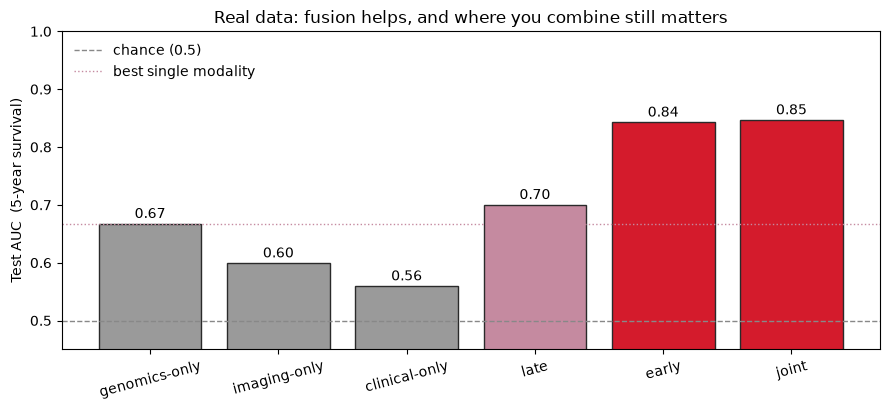

genomics-only    0.667
imaging-only     0.599
clinical-only    0.559
late             0.700
early            0.843
joint            0.847


In [40]:
order  = ["genomics-only","imaging-only","clinical-only","late","early","joint"]
vals   = [scores[k] for k in order]
colors = ["#9A9A9A","#9A9A9A","#9A9A9A","#C58AA0","#D41B2C","#D41B2C"]
fig, ax = plt.subplots(figsize=(9,4.2))
bars = ax.bar(order, vals, color=colors, edgecolor="#2A2A2A")
ax.axhline(0.5, ls="--", lw=1, color="#888", label="chance (0.5)")
best_single = max(scores["genomics-only"], scores["imaging-only"], scores["clinical-only"])
ax.axhline(best_single, ls=":", lw=1, color="#C58AA0", label="best single modality")
ax.set_ylabel("Test AUC  (5-year survival)"); ax.set_ylim(0.45, 1.0)
ax.set_title("Real data: fusion helps, and where you combine still matters")
for b,v in zip(bars, vals): ax.text(b.get_x()+b.get_width()/2, v+0.01, f"{v:.2f}", ha="center", fontsize=10)
ax.legend(loc="upper left", frameon=False); plt.xticks(rotation=15); plt.tight_layout(); plt.show()
print(pd.Series(scores, name="AUC").round(3).to_string())


## Hand-off to Notebook 3 — now you do it

You've now seen the full real-data pipeline: match on the patient, fix scale and dimensionality,
run the four strategies, check subgroups, and handle a missing modality. **Notebook 3 is the
graded assignment**, where you run this yourself and defend your choices:

- Pick your prediction target and justify it.
- Build and compare the fusion strategies on the matched cohort.
- Report subgroup performance and name where your model is weakest.
- Decide how you'd handle missing modalities, and argue for the fusion strategy that fits.

**Three ideas to carry:**
1. On real data, fusion's first win is **complementarity** — even late fusion beats any single modality.
2. **Where you combine still matters** — the interaction is what early and joint recover.
3. The real choice is a **tradeoff**: accuracy on complete patients vs. robustness to missing ones.
